# Chapter 8: Layouts: Many Charts in One Figure

Companion notebook for *Master Data Visualization: A Hands-On Beginner's Guide with Python, Matplotlib, Seaborn & Plotly*.

Run the cells from top to bottom (**Kernel → Restart Kernel and Run All Cells**). The data files this chapter uses are in the same folder as this notebook.

## 8.1 Grids of Charts

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import PercentFormatter, StrMethodFormatter

plt.style.use('book.mplstyle')

In [2]:
categories = pd.read_csv('category_sales.csv')
categories.head(3)

,month,audio,displays,storage,accessories
0,Jan,10100,13200,7900,7000
1,Feb,10300,12400,7600,5600
2,Mar,11300,16000,9300,6200


### `plt.subplots(nrows, ncols)`

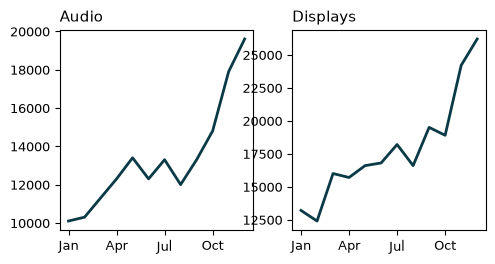

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(5.5, 2.6))
for ax, name in zip(axes, ['audio', 'displays']):
    ax.plot(categories['month'], categories[name])
    ax.set_title(name.title())
    ax.set_xticks([0, 3, 6, 9])
plt.show()

In [4]:
print(type(axes))

<class 'numpy.ndarray'>


### Sharing the y-axis with `sharey`

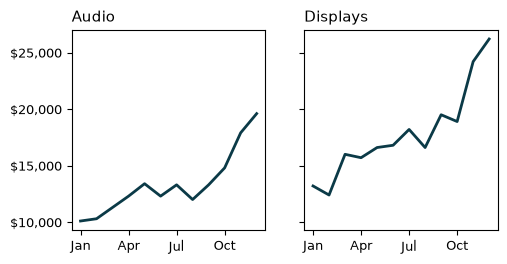

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(5.5, 2.6), sharey=True)
for ax, name in zip(axes, ['audio', 'displays']):
    ax.plot(categories['month'], categories[name])
    ax.set_title(name.title())
    ax.set_xticks([0, 3, 6, 9])
axes[0].yaxis.set_major_formatter(StrMethodFormatter('${x:,.0f}'))
plt.show()

### Grids with several rows

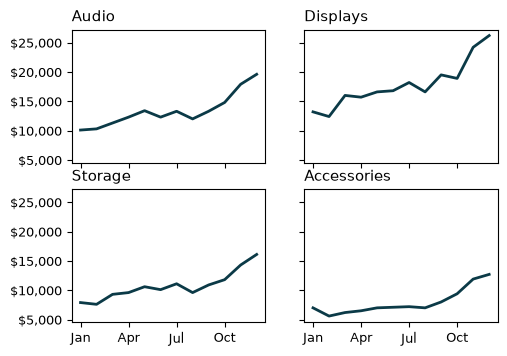

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(5.5, 3.8),
                         sharex=True, sharey=True)
names = ['audio', 'displays', 'storage', 'accessories']
for ax, name in zip(axes.flat, names):
    ax.plot(categories['month'], categories[name])
    ax.set_title(name.title())
axes[0, 0].set_xticks([0, 3, 6, 9])
axes[0, 0].yaxis.set_major_formatter(StrMethodFormatter('${x:,.0f}'))
plt.show()

## 8.2 One Title and Clean Spacing

### `fig.suptitle()`

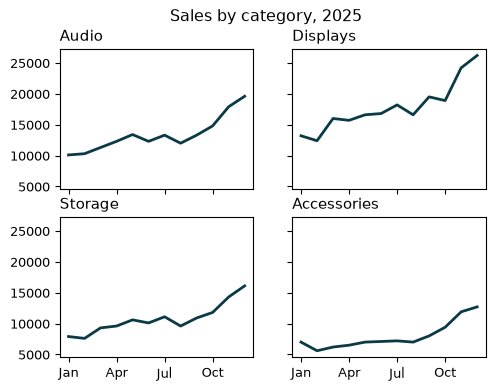

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(5.5, 4),
                         sharex=True, sharey=True)
for ax, name in zip(axes.flat, names):
    ax.plot(categories['month'], categories[name])
    ax.set_title(name.title())
axes[0, 0].set_xticks([0, 3, 6, 9])
fig.suptitle('Sales by category, 2025')
plt.show()

### Fixing overlaps

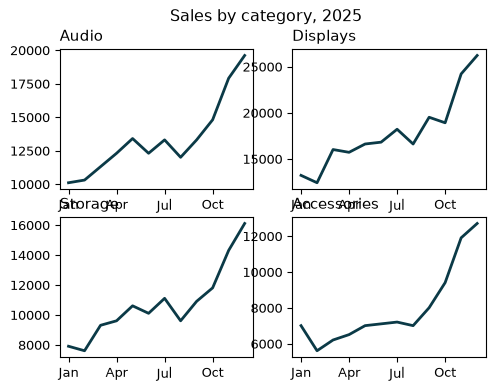

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(5.5, 4))
for ax, name in zip(axes.flat, names):
    ax.plot(categories['month'], categories[name])
    ax.set_title(name.title())
    ax.set_xticks([0, 3, 6, 9])
fig.suptitle('Sales by category, 2025')
plt.show()

### `fig.tight_layout()`

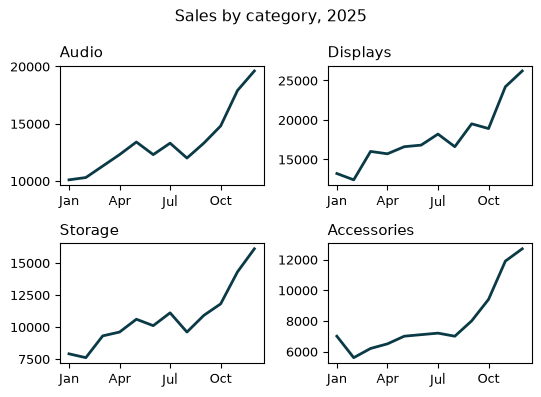

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(5.5, 4))
for ax, name in zip(axes.flat, names):
    ax.plot(categories['month'], categories[name])
    ax.set_title(name.title())
    ax.set_xticks([0, 3, 6, 9])
fig.suptitle('Sales by category, 2025')
fig.tight_layout()
plt.show()

### Constrained layout

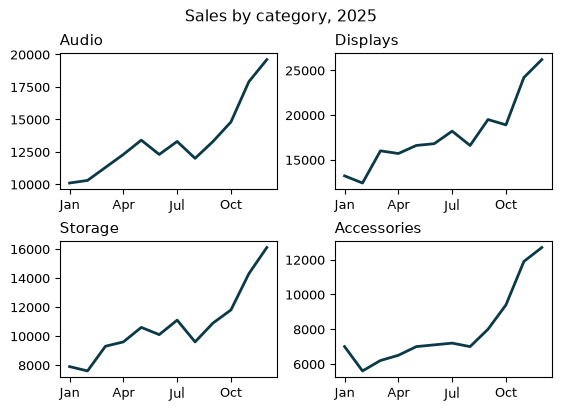

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(5.5, 4),
                         layout='constrained')
for ax, name in zip(axes.flat, names):
    ax.plot(categories['month'], categories[name])
    ax.set_title(name.title())
    ax.set_xticks([0, 3, 6, 9])
fig.suptitle('Sales by category, 2025')
plt.show()

## 8.3 Uneven Layouts with `plt.subplot_mosaic()`

### `plt.subplot_mosaic()`

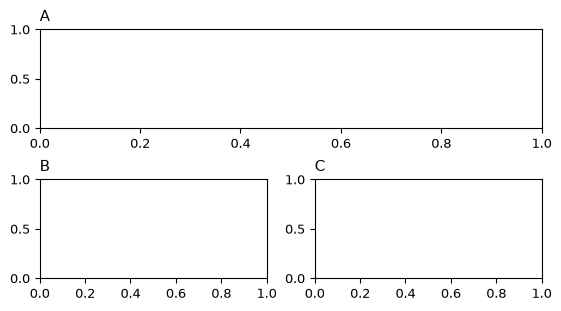

In [11]:
fig, axes = plt.subplot_mosaic('AA;BC', figsize=(5.5, 3),
                               layout='constrained')
for name, ax in axes.items():
    ax.set_title(name)
plt.show()

In [12]:
list(axes)

['A', 'B', 'C']

In [13]:
plan = [['trend', 'trend'],
        ['bars', 'dots']]

In [14]:
shop = pd.read_csv('monthly_shop.csv')
stores = pd.read_csv('store_stats.csv')
totals = categories.drop(columns='month').sum().sort_values()
totals

accessories     95600
storage        128900
audio          160600
displays       214300
dtype: int64

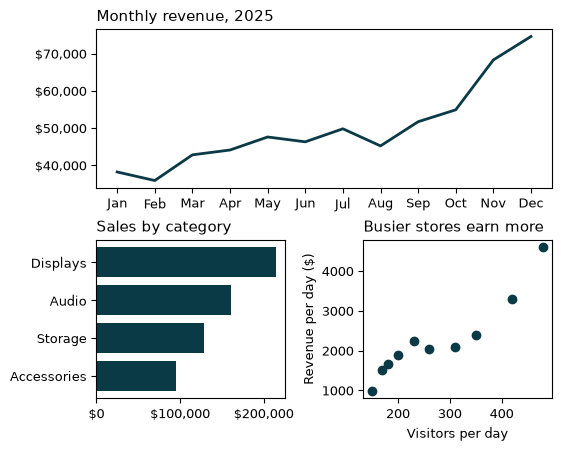

In [15]:
fig, axes = plt.subplot_mosaic(plan, figsize=(5.5, 4.4),
                               layout='constrained')

axes['trend'].plot(shop['month'], shop['revenue'])
axes['trend'].set_title('Monthly revenue, 2025')
axes['trend'].yaxis.set_major_formatter(
    StrMethodFormatter('${x:,.0f}'))

axes['bars'].barh(totals.index.str.title(), totals)
axes['bars'].set_title('Sales by category')
axes['bars'].set_xticks([0, 100000, 200000])
axes['bars'].xaxis.set_major_formatter(
    StrMethodFormatter('${x:,.0f}'))

axes['dots'].scatter(stores['visitors'], stores['daily_revenue'])
axes['dots'].set_title('Busier stores earn more')
axes['dots'].set_xlabel('Visitors per day')
axes['dots'].set_ylabel('Revenue per day ($)')
plt.show()

## 8.4 Two Y-Axes with `ax.twinx()`

### `ax.twinx()`

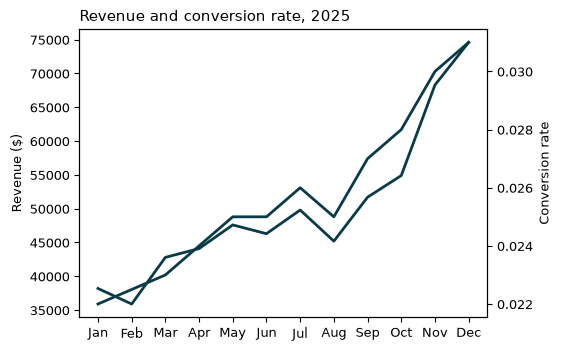

In [16]:
fig, ax = plt.subplots(layout='constrained')
ax2 = ax.twinx()
ax.plot(shop['month'], shop['revenue'])
ax2.plot(shop['month'], shop['conversion'])
ax.set_title('Revenue and conversion rate, 2025')
ax.set_ylabel('Revenue ($)')
ax2.set_ylabel('Conversion rate')
plt.show()

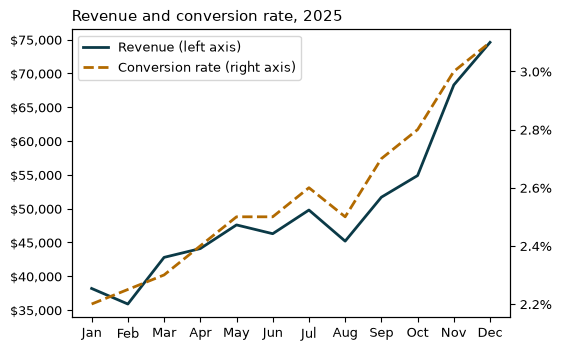

In [17]:
fig, ax = plt.subplots(layout='constrained')
ax2 = ax.twinx()
line1, = ax.plot(shop['month'], shop['revenue'],
                 label='Revenue (left axis)')
line2, = ax2.plot(shop['month'], shop['conversion'],
                  color='#b26a00', linestyle='--',
                  label='Conversion rate (right axis)')
ax.set_title('Revenue and conversion rate, 2025')
ax.yaxis.set_major_formatter(StrMethodFormatter('${x:,.0f}'))
ax2.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=1))
ax.legend(handles=[line1, line2], loc='upper left')
plt.show()

### Stacked charts as the alternative

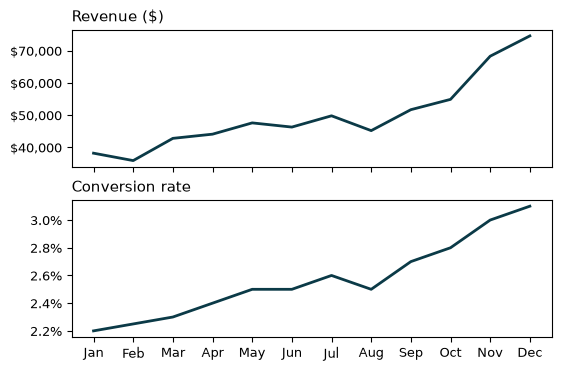

In [18]:
fig, (top, bottom) = plt.subplots(2, 1, figsize=(5.5, 3.6),
                                  sharex=True,
                                  layout='constrained')
top.plot(shop['month'], shop['revenue'])
top.set_title('Revenue ($)')
top.yaxis.set_major_formatter(StrMethodFormatter('${x:,.0f}'))
bottom.plot(shop['month'], shop['conversion'])
bottom.set_title('Conversion rate')
bottom.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=1))
plt.show()